# RetroMorph AI: Image Readiness ML Experiments
## Step 1: Project Objective and Dataset Description

**Project Goal:**  
Train, evaluate, and serialize a machine learning classifier that assesses whether an uploaded user photograph is suitable for retro PlayStation 1 (PS1) 3D character generation (`ready`) or whether quality issues warrant a request to retake the photo (`retake`).

**Key Requirements:**
- Train a model using scikit-learn on extracted computer vision features.
- Evaluate on a held-out test split.
- Export the fitted pipeline to `image_quality_model.pkl`.
- Reload and demonstrate inference on sample images.

**Quality Attributes Evaluated:**
- Clarity & blur (Laplacian variance)
- Lighting & exposure (mean brightness, RMS contrast)
- Resolution & aspect ratio
- Edge detail & subject centering


In [1]:
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Add ml/src to path
sys.path.append(os.path.abspath("../src"))
from features import FEATURE_NAMES, extract_image_features, analyze_image_quality_rules

print("Dependencies successfully loaded.")


Dependencies successfully loaded.


## Step 2: Data Loading and Label Inspection

We load the dataset generated from controlled image quality samples containing balanced labels (`ready` and `retake`).


In [2]:
data_path = "../data/dataset.csv"
df = pd.read_csv(data_path)
print(f"Total dataset shape: {df.shape}")
print("\nLabel distribution:")
print(df["label"].value_counts())
df.head()


Total dataset shape: (400, 14)

Label distribution:
label
ready     200
retake    200
Name: count, dtype: int64


,width,height,aspect_ratio,resolution_mp,brightness_mean,brightness_std,contrast_rms,blur_score,edge_density,color_variance,subject_framing_score,label,reason,filename
0,512.0,512.0,1.00,0.2621,91.62,26.71,26.71,13.96,0.00489,28.57,2.099,ready,"Optimal clarity, balanced lighting, centered s...",sample_0000_ready.jpg
1,768.0,1024.0,0.75,0.7864,30.36,5.67,5.67,263.95,0.00000,7.76,0.000,retake,Severe underexposure; person silhouette barely...,sample_0001_retake.jpg
2,1024.0,512.0,2.00,0.5243,96.75,32.84,32.84,363.80,0.00215,34.75,1.974,ready,"Optimal clarity, balanced lighting, centered s...",sample_0002_ready.jpg
3,640.0,512.0,1.25,0.3277,113.08,3.99,3.99,207.75,0.00000,7.48,0.000,retake,"Flat, low-contrast lighting",sample_0003_retake.jpg
4,768.0,800.0,0.96,0.6144,85.73,28.59,28.59,434.17,0.00324,34.72,2.216,ready,"Optimal clarity, balanced lighting, centered s...",sample_0004_ready.jpg


## Step 3: Exploratory Data Analysis (EDA)

We explore feature distributions between `ready` and `retake` classes, focusing on blur score, brightness, contrast, and resolution.


C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_7888\586979061.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y="blur_score", ax=axes[0, 0], palette="Set2")
C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_7888\586979061.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y="contrast_rms", ax=axes[1, 0], palette="Pastel1")


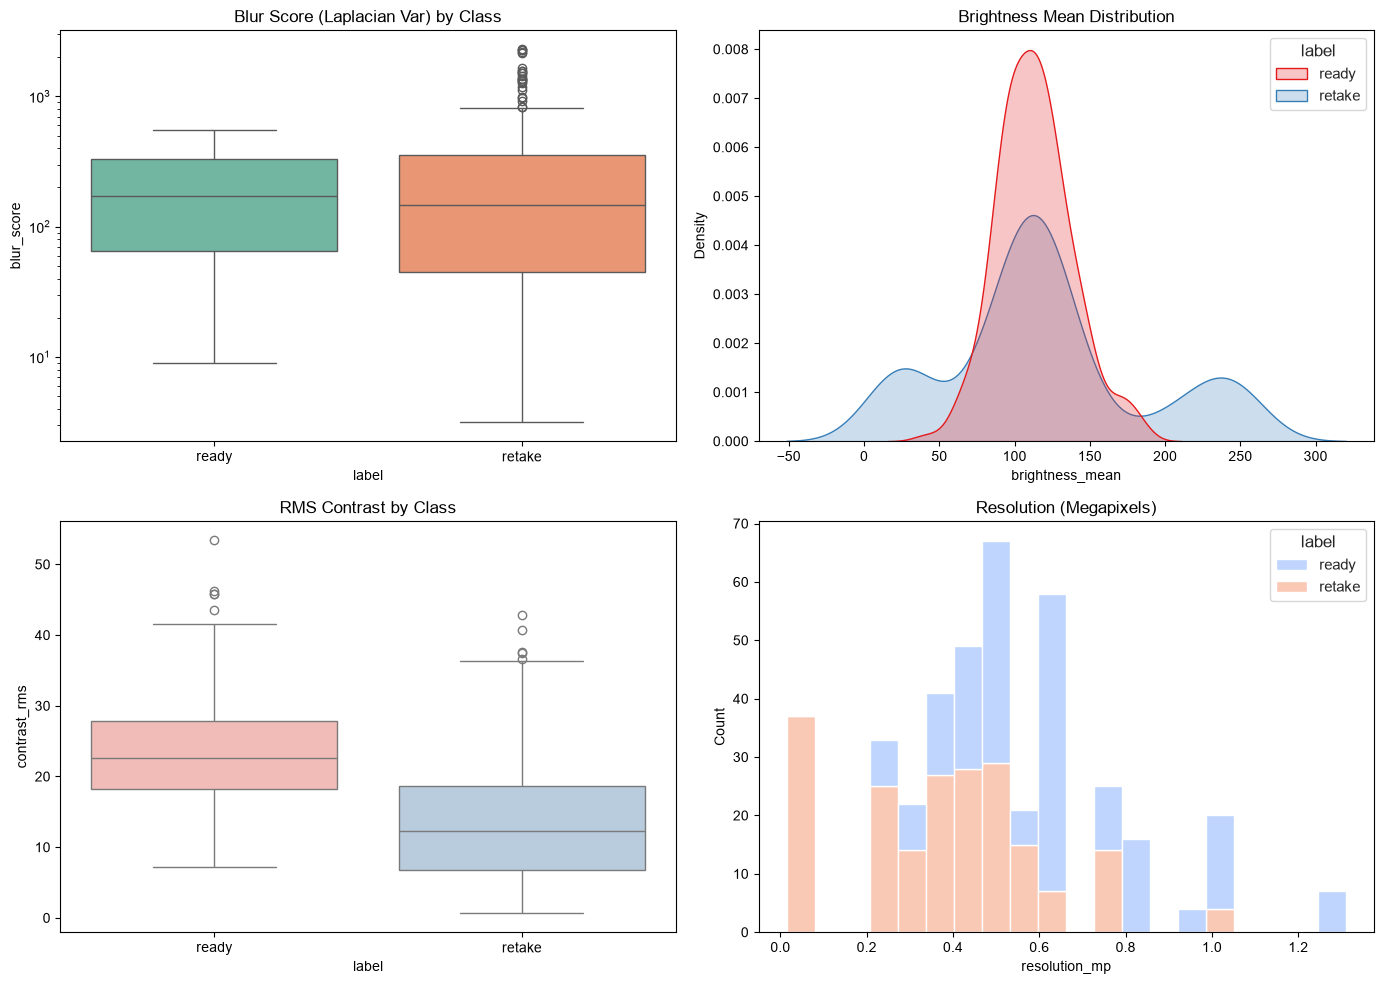

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.set_theme(style="whitegrid")

# 1. Blur score distribution (log scale for Laplacian variance)
sns.boxplot(data=df, x="label", y="blur_score", ax=axes[0, 0], palette="Set2")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Blur Score (Laplacian Var) by Class")

# 2. Brightness mean
sns.kdeplot(data=df, x="brightness_mean", hue="label", fill=True, ax=axes[0, 1], palette="Set1")
axes[0, 1].set_title("Brightness Mean Distribution")

# 3. RMS Contrast
sns.boxplot(data=df, x="label", y="contrast_rms", ax=axes[1, 0], palette="Pastel1")
axes[1, 0].set_title("RMS Contrast by Class")

# 4. Resolution Megapixels
sns.histplot(data=df, x="resolution_mp", hue="label", multiple="stack", ax=axes[1, 1], palette="coolwarm")
axes[1, 1].set_title("Resolution (Megapixels)")

plt.tight_layout()
plt.show()


## Step 4: Feature Correlation Analysis

We calculate the Pearson correlation matrix across numerical features to verify relationships and feature diversity.


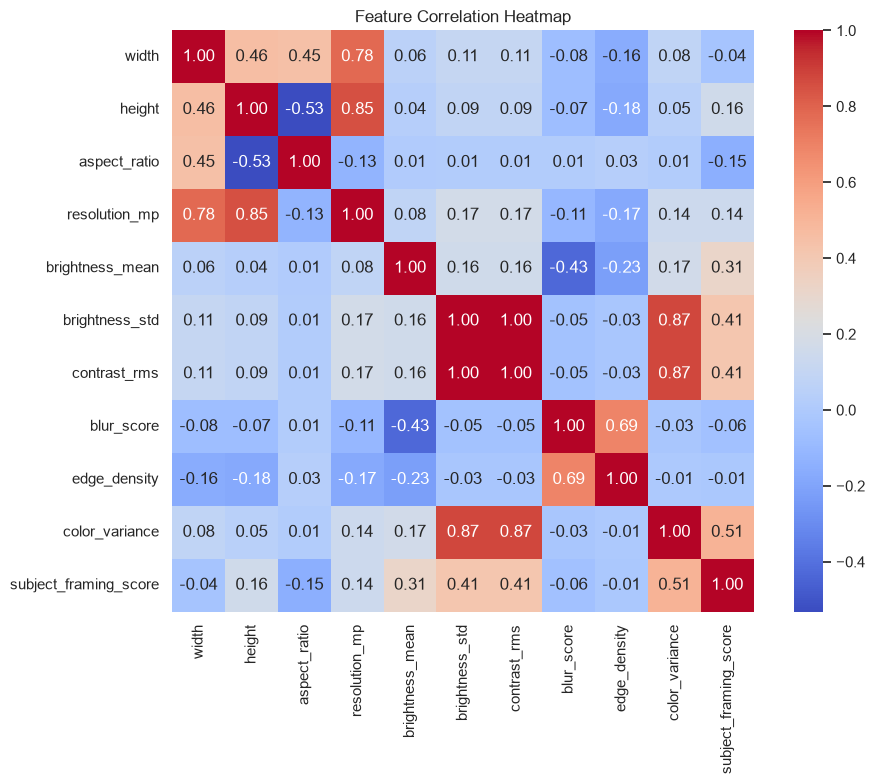

In [4]:
plt.figure(figsize=(10, 8))
corr = df[FEATURE_NAMES].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


## Step 5: Train / Test Split

We perform an 80/20 stratified train/test split to preserve class proportions for rigorous evaluation.


In [5]:
X = df[FEATURE_NAMES]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")


Training set: 320 samples
Testing set:  80 samples


## Step 6: Baseline Model Comparison

We compare a Dummy classifier (majority class) and a simple Logistic Regression model against our proposed ensemble classifier.


In [6]:
# Baseline 1: Dummy
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(X_test))

# Baseline 2: Logistic Regression with Scaling
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(random_state=42))
])
lr_pipe.fit(X_train, y_train)
lr_acc = accuracy_score(y_test, lr_pipe.predict(X_test))

print(f"Dummy Classifier Accuracy:        {dummy_acc:.4f}")
print(f"Logistic Regression Accuracy:    {lr_acc:.4f}")


Dummy Classifier Accuracy:        0.5000
Logistic Regression Accuracy:    0.9500


## Step 7: Model Training & Cross-Validation

We train a Random Forest Pipeline with feature scaling and evaluate using 5-fold Stratified Cross-Validation.


In [7]:
rf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=6,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring="f1_macro")

print(f"5-Fold CV Macro F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# Fit final model
rf_pipeline.fit(X_train, y_train)
print("Pipeline fitted successfully.")


5-Fold CV Macro F1: 0.9625 (+/- 0.0234)
Pipeline fitted successfully.


## Step 8: Comprehensive Model Evaluation

We evaluate the trained model on the held-out test split, reporting Accuracy, Precision, Recall, Macro F1, and plotting the Confusion Matrix.


Classification Report:

              precision    recall  f1-score   support

       ready       1.00      0.90      0.95        40
      retake       0.91      1.00      0.95        40

    accuracy                           0.95        80
   macro avg       0.95      0.95      0.95        80
weighted avg       0.95      0.95      0.95        80



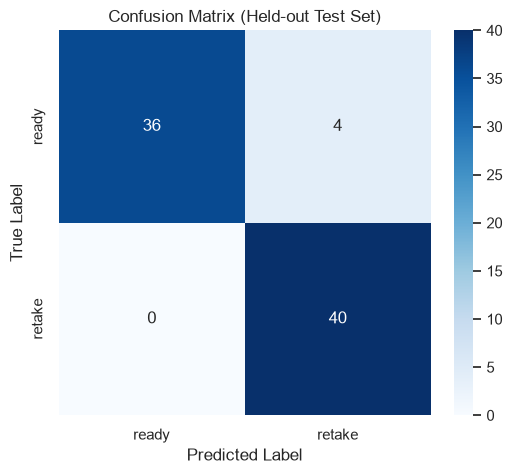

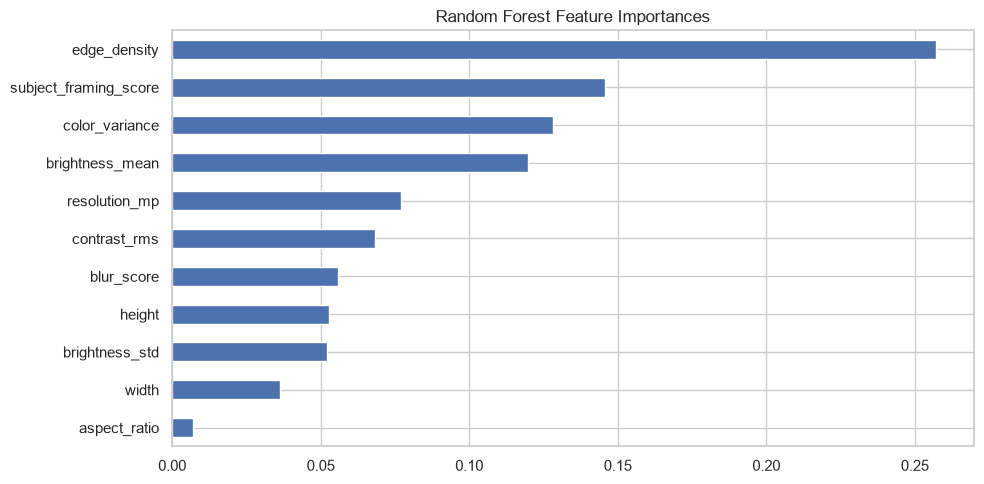

In [8]:
y_pred = rf_pipeline.predict(X_test)
y_proba = rf_pipeline.predict_proba(X_test)

print("Classification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=rf_pipeline.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=rf_pipeline.classes_, yticklabels=rf_pipeline.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Held-out Test Set)")
plt.show()

# Top Feature Importances
rf = rf_pipeline.named_steps["classifier"]
importances = pd.Series(rf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
importances.plot(kind="barh", color="#4C72B0")
plt.title("Random Forest Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## Step 9: Save Fitted Pipeline to .pkl Artifact

We bundle the fitted pipeline with class mappings and metadata into `ml/artifacts/image_quality_model.pkl`.


In [9]:
artifact = {
    "pipeline": rf_pipeline,
    "feature_names": FEATURE_NAMES,
    "classes": list(rf_pipeline.classes_),
    "metrics": {
        "test_accuracy": float(accuracy_score(y_test, y_pred)),
        "cv_macro_f1": float(cv_scores.mean())
    }
}

os.makedirs("../artifacts", exist_ok=True)
joblib.dump(artifact, "../artifacts/image_quality_model.pkl")
print("Saved model artifact to ml/artifacts/image_quality_model.pkl")


Saved model artifact to ml/artifacts/image_quality_model.pkl


## Step 10: Reload Artifact & Demonstrate Inference

We reload the `.pkl` artifact from disk to confirm clean deserialization and demonstrate end-to-end inference on test cases.


In [10]:
from predict import predict_image_quality

# Test sample predictions
sample_files = [f for f in os.listdir("../data/samples") if f.endswith(".jpg")][:3]
for s in sample_files:
    sample_path = os.path.join("../data/samples", s)
    res = predict_image_quality(sample_path)
    print(f"\nFile: {s}")
    print(f"Status:      {res['status'].upper()} (Confidence: {res['confidence']*100:.1f}%)")
    print(f"Summary:     {res['summary']}")
    print(f"Suggestions: {res['suggestions']}")



File: sample_0000_ready.jpg
Status:      READY (Confidence: 78.0%)
Summary:     Image is suitable for PS1 character generation.
Suggestions: ['Image clarity is good. Proceed with generation.']



File: sample_0001_retake.jpg
Status:      RETAKE (Confidence: 98.5%)
Summary:     Image has quality issues that will affect 3D generation. Consider retaking or replacing.
Suggestions: ['Hold the camera steady or use better lighting to prevent motion blur.', 'Ensure adequate frontal lighting so facial features are visible.', 'Avoid flat gray lighting; distinct clothing and face contours help 3D reconstruction.']

File: sample_0002_ready.jpg
Status:      READY (Confidence: 87.0%)
Summary:     Image is suitable for PS1 character generation.
Suggestions: ['Image clarity is good. Proceed with generation.']
